In [4]:
# ============================================================
# 0. Importing libraries and modules
# ============================================================
import pandas as pd
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import urllib.request
import io
import os
from scipy.stats import kurtosis
from scipy.signal import welch              # Analyse spectral Welch
from scipy.fftpack import fft, fftfreq      # Analyse spectral FFT
import scipy.signal as sci
from scipy.signal import hilbert

# ============================================================
# 1. Chargement des données 
# ============================================================

    # ==================
    # 1.1 Contexte
    # ==================

# --- Fréquences caractéristiques des roulements --- #
# Source : https://engineering.case.edu/bearingdatacenter/bearing-information
COEFF_Freq_DE = {"BPFI": 5.4152, "BPFO": 3.5848, "FTF": 0.39828, "BSF": 4.7135} 
COEFF_Freq_FE = {"BPFI": 4.9469, "BPFO": 3.0530, "FTF": 0.3817, "BSF": 3.9874}
# BPFI (Ball Pass Frequency Inner)      >> Piste intérieur
# BPFO (Ball Pass Frequency Outer)      >> Piste extérieur
# BSF (Ball Spin Frequency)             >> Bille
# FTF (Fundamental Train Frequency)     >> Cage

FS = 12000  # fréquence d'échantillonnage (Hz)

    # ==================
    # 1.2 Data
    # ==================
# Local data path
LocalDataPath = "/home/ubuntu/data/"

# Data loading
def charger_signaux(chemin_mat):
    # Si c'est un dossier, prend le premier fichier .mat
    if os.path.isdir(LocalDataPath + chemin_mat):
        fichier = next(f for f in os.listdir(LocalDataPath + chemin_mat) if f.endswith('.mat'))
        chemin_mat = chemin_mat.rstrip('/') + '/' + fichier

    mat = scipy.io.loadmat(LocalDataPath+chemin_mat)
    signaux = {}
    for cle, valeur in mat.items():
        if cle.startswith("__"):
            continue
        if cle.endswith("_DE_time"):
            signaux["DE"] = np.ravel(valeur)
        elif cle.endswith("_FE_time"):
            signaux["FE"] = np.ravel(valeur)
        elif cle.endswith("_BA_time"):
            signaux["BA"] = np.ravel(valeur)
        elif cle.endswith("RPM"):
            signaux["RPM"] = float(valeur[0][0])
    return signaux

# ============================================================
# 2. Chargement des données
# ============================================================
normal = charger_signaux('Normal_Baseline_Data/Motor_Load_1/Normal_1')
fault = charger_signaux('12k_Fan_End_Bearing_Fault/Fault_Diam_007/Motor_Load_1/IR007_1')
# fault = charger_signaux('12k_Fan_End_Bearing_Fault/Fault_Diam_007/Motor_Load_1/B007_1')
# fault = charger_signaux('12k_Fan_End_Bearing_Fault/Fault_Diam_007/Motor_Load_1/OR007@6_1')


# --- Dictionnaire de signaux
signaux = {
    "Normal Drive": normal.get("DE"),
    "Normal Fan":   normal.get("FE"),
    "Fault Drive":  fault.get("DE"),
    "Fault Fan":    fault.get("FE"),
    "Fault Base":   fault.get("BA"),
    "RPM":          fault.get("RPM"),
}
# supprime les vides
signaux = {nom: sig for nom, sig in signaux.items() if sig is not None}
rpm=signaux["RPM"]

# ============================================================
# 2. Définitions des fontions
# ============================================================

# --- Calcul de indicateurs de base d'un signal --- #
def indicateurs(signal):
    return {
        "N points":  len(signal),
        "Durée (sec)":  len(signal)/FS,
        "Moyenne":   np.mean(signal),
        "Écart-type": np.std(signal),
        "RMS":       np.sqrt(np.mean(signal**2)),
        "Crête":     np.max(np.abs(signal)),
        "Facteur crête": np.max(np.abs(signal)) / np.sqrt(np.mean(signal**2)),
        "Kurtosis":  kurtosis(signal, fisher=False)
    }

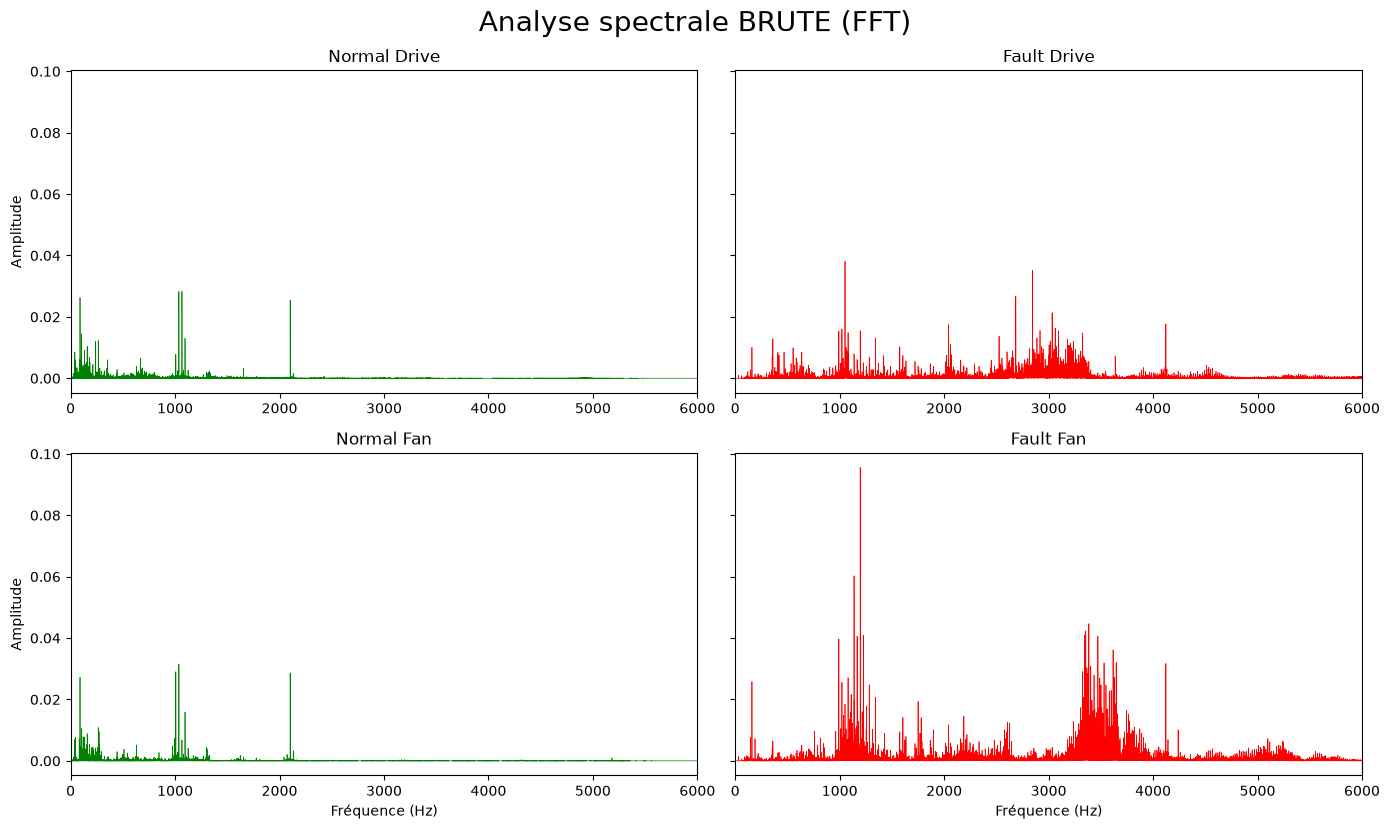

In [5]:
# ============================================================
# 5. Analyse spectrale (FFT)
# ============================================================
def spectre_fft(signal, fs):
    n = len(signal)
    spectre = np.abs(fft(signal))[: n // 2] * 2 / n
    freqs = fftfreq(n, d=1 / fs)[: n // 2]
    return freqs, spectre

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
for i, (titre, sig) in enumerate([("Normal Drive", signaux["Normal Drive"]),
                                   ("Normal Fan",   signaux["Normal Fan"])]):
    freqs, spectre = spectre_fft(sig, FS)
    axes[i, 0].plot(freqs, spectre, color="g", lw=0.5)
    axes[i, 0].set_title(titre)
    axes[i, 0].set_xlim(0, FS / 2)

for i, (titre, sig) in enumerate([("Fault Drive", signaux["Fault Drive"]),
                                  ("Fault Fan",   signaux["Fault Fan"])]):
                                  #("Fault Base",  signaux["Fault Base"])]): exlusion de la base car créer un pique dans le graphe
    freqs, spectre = spectre_fft(sig, FS)
    axes[i, 1].plot(freqs, spectre, color="r", lw=0.5)
    axes[i, 1].set_title(titre)
    axes[i, 1].set_xlim(0, FS / 2)

for ax in axes[:, 0]: ax.set_ylabel("Amplitude")
for ax in axes[1, :]:   ax.set_xlabel("Fréquence (Hz)")

plt.tight_layout()
fig.suptitle("Analyse spectrale BRUTE (FFT)", fontsize=20, y=1.03)
plt.show()

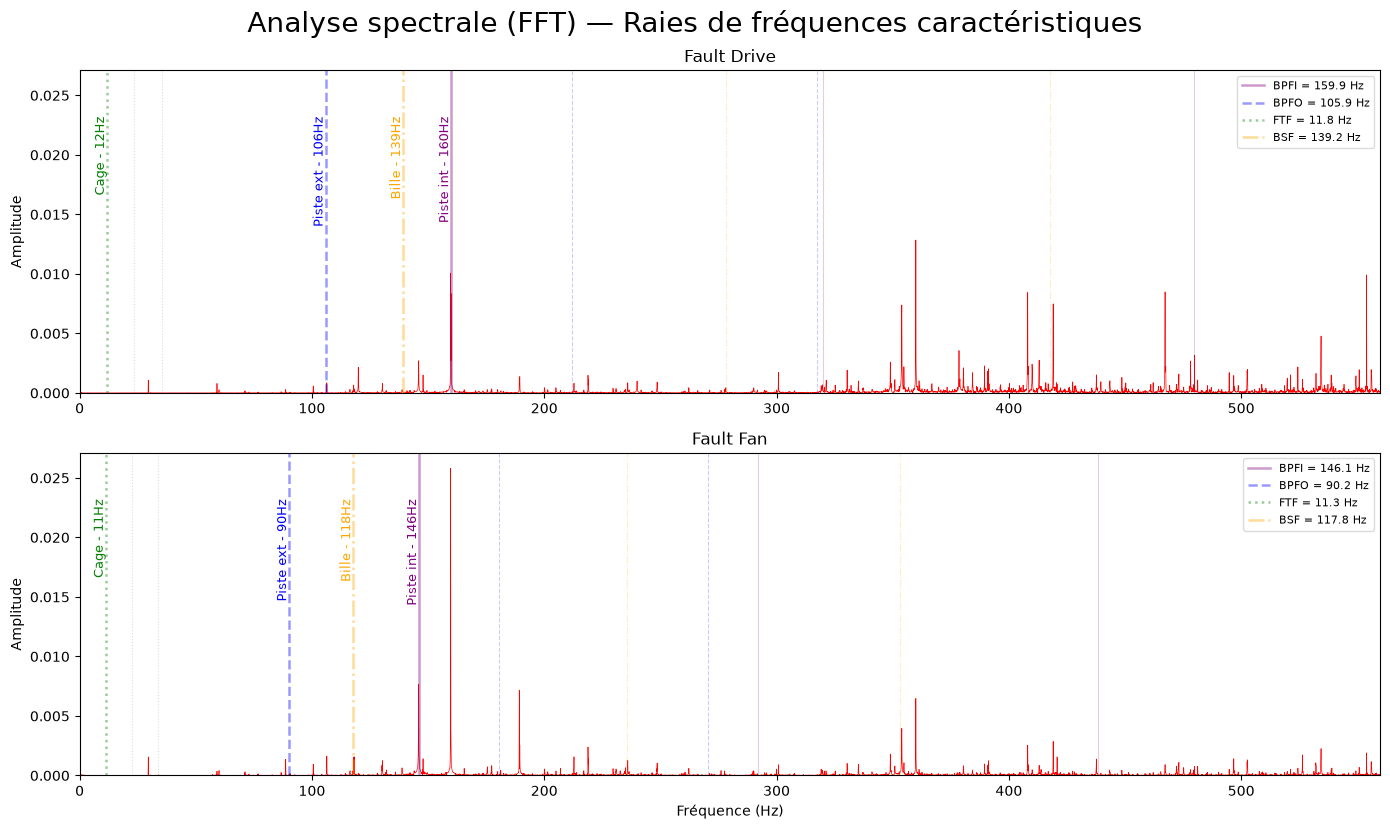

Analyse du graphique :
1. On voit que le pic le plus important se trouve sur l'accéléromètre FAN ce qui laisse à penser que le défaut se trouve sur ce roulement (visible également avec les indicateurs de crête et Kurtosis).
2. On constate un pic aligné sur la raie de la piste intérieure, donc probablement un défaut de piste intérieure (également sur le 3eme harmonique)
 . On constate également un pic sur la raie de bille, mais plus faible que celui de la piste intérieure
3. Le pic le plus important ne correspond à aucune des raies, ce qui laisse à penser que l'analyse n'est pas correcte et/ou complète.

L'analyse ne permettant pas d'avoir de certitude, nous pouvons tout de même conclure que le plus probable est un défaut de piste intérieure du roulement de ventilateur (FAN)
Remarque : dans les data, le rpm est de 1732 tours/minute, alors que sur le site, il est donné à 1772.
           Si on prend le rpm data (1732), nous n'avons pas de correspondace des pics, on utilise donc le rpm = 

In [ ]:
# ============================================================
# 5. Analyse spectrale (FFT) + raies caractéristiques
# ============================================================
def freqs_caracteristiques(rpm, roulement="DE"):
    coeffs = COEFF_Freq_FE if roulement == "FE" else COEFF_Freq_DE
    Fr = rpm / 60
    return {nom: coef * Fr for nom, coef in coeffs.items()}

# On modifie le rpm avec celui indiqué sur le site, sinon les raies ne correspondent pas
rpm = 1772

# --- Styles distincts par défaut : (couleur, style de trait) ---
styles_raies = {
    "BPFI": ("purple", "-"),    # trait plein
    "BPFO": ("blue",   "--"),   # tirets
    "BSF":  ("orange", "-."),   # trait-point
    "FTF":  ("green",  ":"),    # pointillés
}


graph_XMAX = 0
y_max = 0

for i, (titre, sig) in enumerate([("Fault Drive", signaux["Fault Drive"]),
                                  ("Fault Fan",   signaux["Fault Fan"])]):                             
    roulement = "DE" if "Drive" in titre else "FE"
    FC = freqs_caracteristiques(rpm, roulement)
    if FC["BPFI"] * 3.5 > graph_XMAX: graph_XMAX=FC["BPFI"] * 3.5

    masque = (freqs >= 0) & (freqs <= graph_XMAX)
    if spectre[masque].max() > y_max: 
        y_max = spectre[masque].max()
        y_texte = y_max * 0.9





fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=True)

for i, (titre, sig) in enumerate([("Fault Drive", signaux["Fault Drive"]),
                                  ("Fault Fan",   signaux["Fault Fan"])]):
                                  
    roulement = "DE" if "Drive" in titre else "FE"
    FC = freqs_caracteristiques(rpm, roulement)

    libelles_raies = {
        "BPFI": "Piste int - "+str(round(FC["BPFI"]))+"Hz",
        "BPFO": "Piste ext - "+str(round(FC["BPFO"]))+"Hz",
        "BSF":  "Bille - "+str(round(FC["BSF"]))+"Hz",
        "FTF":  "Cage - "+str(round(FC["FTF"]))+"Hz",
    }


    freqs, spectre = spectre_fft(sig, FS)
    axes[i].plot(freqs, spectre, color="r", lw=0.5)
    axes[i].set_title(titre)
    axes[i].set_xlim(0, graph_XMAX)
    axes[i].set_ylim(0, y_max * 1.05)


    # --- Raies caractéristiques + harmoniques ---
    for nom, val in FC.items():
        couleur, ls = styles_raies[nom]
        libelle = libelles_raies[nom]

        # Fondamentale : raie principale bien visible
        axes[i].axvline(val, color=couleur, ls=ls, lw=1.8, alpha=0.4,
                        label=f"{nom} = {val:.1f} Hz")

        # Harmoniques (2x, 3x) : plus fines et plus transparentes
        for k in range(2, 4):
            f_raie = k * val
            if f_raie < graph_XMAX:
                axes[i].axvline(f_raie, color=couleur, ls=ls,
                                lw=0.8, alpha=0.2)

        axes[i].text(val, y_texte, libelle,
                     rotation=90, fontsize=9, color=couleur,
                     ha="right", va="top")

    axes[i].legend(loc="upper right", fontsize=8, framealpha=0.7)

for ax in axes:
    ax.set_ylabel("Amplitude")
axes[-1].set_xlabel("Fréquence (Hz)")

plt.tight_layout()
fig.suptitle("Analyse spectrale (FFT) — Raies de fréquences caractéristiques", fontsize=20, y=1.03)
plt.show()

print("Analyse du graphique :\n1. On voit que le pic le plus important se trouve sur l'accéléromètre FAN ce qui laisse à penser que le défaut se trouve sur ce roulement (visible également avec les indicateurs de crête et Kurtosis)." \
"\n2. On constate un pic aligné sur la raie de la piste intérieure, donc probablement un défaut de piste intérieure (également sur le 3eme harmonique)" \
"\n . On constate également un pic sur la raie de bille, mais plus faible que celui de la piste intérieure" \
"\n3. Le pic le plus important ne correspond à aucune des raies, ce qui laisse à penser que l'analyse n'est pas correcte et/ou complète." \
"\n\nL'analyse ne permettant pas d'avoir de certitude, nous pouvons tout de même conclure que le plus probable est un défaut de piste intérieure du roulement de ventilateur (FAN)" \
"\nRemarque : dans les data, le rpm est de 1732 tours/minute, alors que sur le site, il est donné à 1772." \
"\n           Si on prend le rpm data (1732), nous n'avons pas de correspondace des pics, on utilise donc le rpm = 1772.")

In [3]:
# ============================================================
# 6. Analyse d'enveloppe (filtre passe-bande + Hilbert + FFT)
# ============================================================
def spectre_enveloppe(signal, fs, bande=(1000, 4000), n_fft=2**14):
    """Analyse d'enveloppe :
    1. Filtre passe-bande autour d'une bande de résonance
    2. Démodulation par transformation de Hilbert -> enveloppe des chocs
    3. FFT de l'enveloppe -> les raies BPFI/BPFO ressortent nettement
    """
    # --- 1. Filtre passe-bande (zero-phase, pas de décalage temporel) ---
    sos = sci.butter(4, [bande[0]/(fs/2), bande[1]/(fs/2)],
                     btype='bandpass', output='sos')
    signal_filtre = sci.sosfiltfilt(sos, signal)

    # --- 2. Démodulation : enveloppe via Hilbert ---
    enveloppe = np.abs(hilbert(signal_filtre))
    enveloppe = enveloppe - np.mean(enveloppe)   # retire la composante continue

    fenetre = np.hanning(len(enveloppe))         # limite le spectral leakage

    # --- 3. FFT de l'enveloppe ---
    spectre = np.abs(np.fft.rfft(enveloppe * fenetre, n=n_fft))
    freqs = np.fft.rfftfreq(n_fft, d=1/fs)
    spectre = spectre / np.sum(fenetre) * 2       # normalisation en amplitude

    return freqs, spectre


# --- Paramètres de la bande de résonance (à ajuster selon la machine) ---
BANDE_RESONANCE = (1000, 4000)   # Hz
rpm=1772

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharey=True)

for i, (titre, sig) in enumerate([("Fault Drive", signaux["Fault Drive"]),
                                  ("Fault Fan",   signaux["Fault Fan"])]):
    # Roulement concerné : Drive -> DE, Fan -> FE
    roulement = "DE" if "Drive" in titre else "FE"
    FC = freqs_caracteristiques(rpm, roulement)

    freqs_env, spectre_env = spectre_enveloppe(sig, FS, bande=BANDE_RESONANCE)

    axes[i].plot(freqs_env, spectre_env, color="r", lw=0.5)
    axes[i].set_title(titre + f"  (filtre {BANDE_RESONANCE[0]}–{BANDE_RESONANCE[1]} Hz)")
    axes[i].set_xlim(0, graph_XMAX)

    masque = (freqs_env >= 0) & (freqs_env <= graph_XMAX)
    y_max = spectre_env[masque].max()
    axes[i].set_ylim(0, y_max * 1.05)
    y_texte = y_max * 0.8


    # --- Raies caractéristiques + harmoniques (mêmes styles qu'avant) ---
    for nom, val in FC.items():
        couleur, ls = styles_raies[nom]
        axes[i].axvline(val, color=couleur, ls=ls, lw=1.8, alpha=0.4,
                        label=f"{nom} = {val:.1f} Hz")
        for k in range(2, 4):                    # harmoniques 2x, 3x
            f_raie = k * val
            if f_raie < graph_XMAX:
                axes[i].axvline(f_raie, color=couleur, ls=ls,
                                lw=0.8, alpha=0.2)
            if i == 1:
                axes[i].text(val, y_texte,
                     f"{nom} harmonique {k} = {val*k:.1f} Hz",
                     fontsize=9, color=couleur,
                     ha="right", va="top")

        axes[i].text(val, y_texte,
                     f"{nom} = {val:.1f} Hz",
                     rotation=90, fontsize=9, color=couleur,
                     ha="right", va="top")

    axes[i].legend(loc="upper right", fontsize=8, framealpha=0.7)

for ax in axes:
    ax.set_ylabel("Amplitude d'enveloppe")
axes[-1].set_xlabel("Fréquence (Hz)")




plt.tight_layout()
fig.suptitle("Analyse d'enveloppe (Hilbert) — Raies de fréquences caractéristiques",
             fontsize=20, y=1.03)
plt.show()

NameError: name 'plt' is not defined

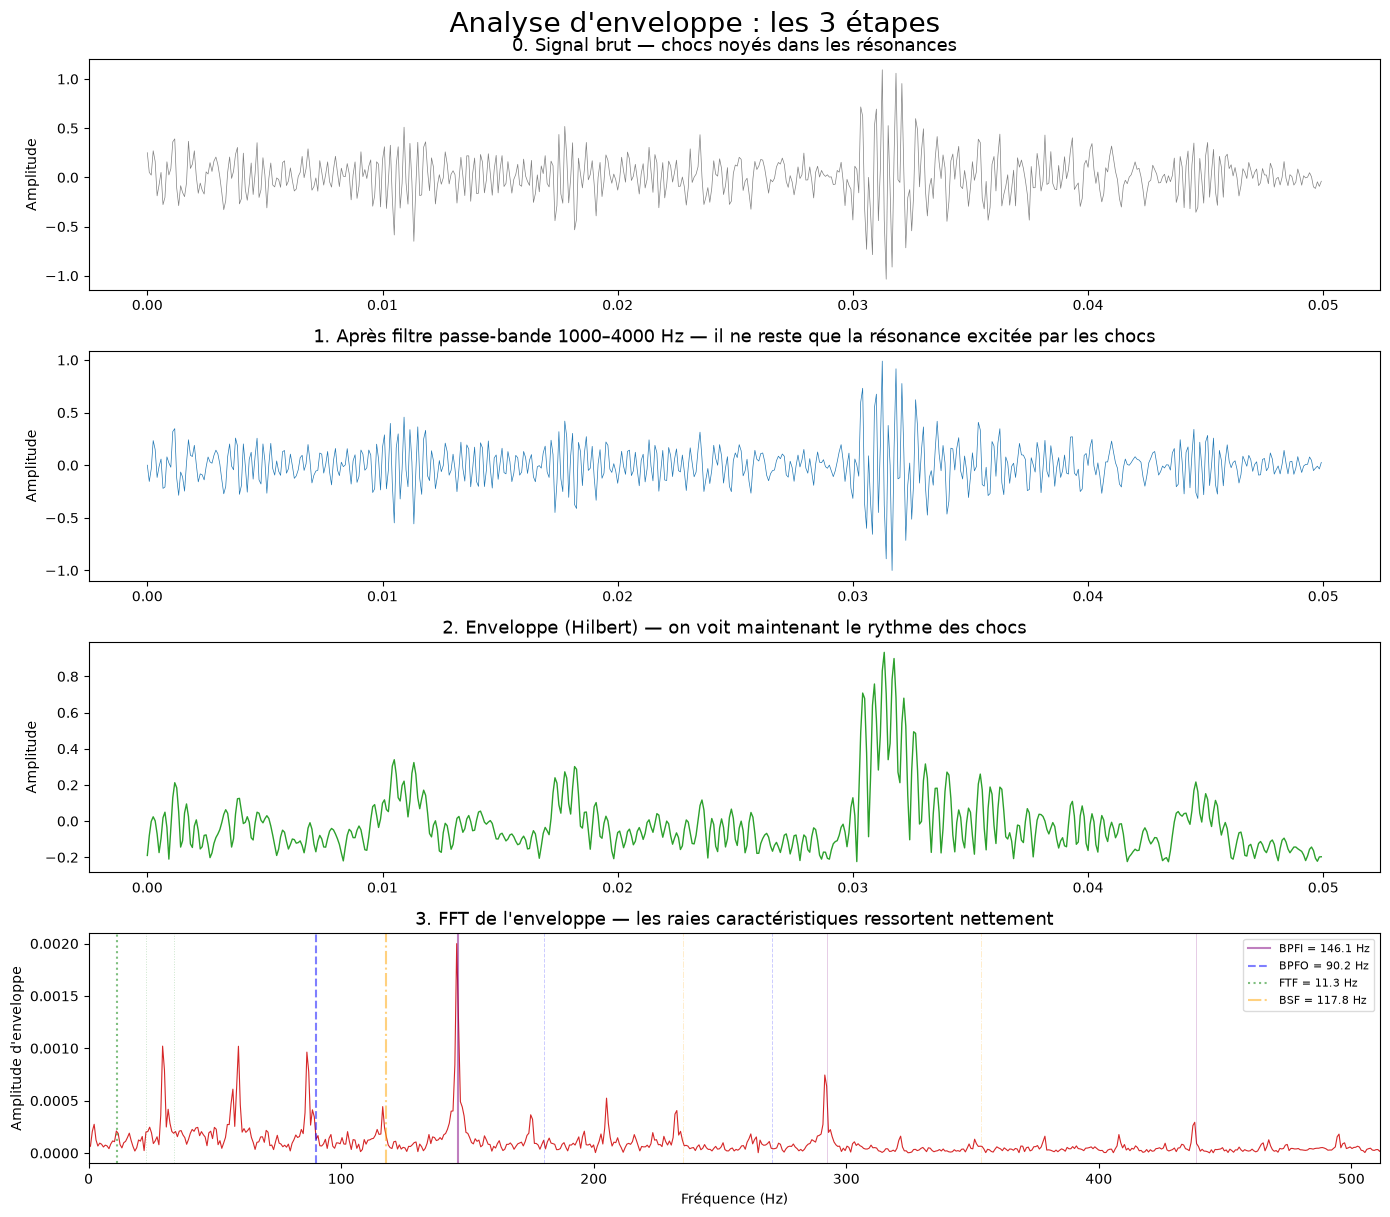

In [15]:
# ============================================================
# 6-bis. Illustration pédagogique : les 3 étapes de l'analyse d'enveloppe
# ============================================================
from scipy.signal import hilbert

# ------------------------------------------------------------
# Étape 0 : signal de démonstration (optionnel)
# -> décommente la ligne "SIG =" correspondante :
#    - soit un signal SYNTHÉTIQUE parfaitement contrôlé (chocs périodiques)
#    - soit ton vrai signal CWRU
# ------------------------------------------------------------
def signal_demo(fs=12000, duree=1.0, f_choc=103.36, f_res=2500):
    """Chocs périodiques à f_choc (≈BPFO) excitant une résonance à f_res."""
    t = np.arange(0, duree, 1/fs)
    signal = np.zeros_like(t)
    periode = 1/f_choc
    for t0 in np.arange(0, duree, periode):
        # Sinusoïde amortie = empreinte d'un choc sur la structure
        choc = np.sin(2*np.pi*f_res*(t - t0)) * np.exp(-80*(t - t0))
        signal += np.where(t >= t0, choc, 0)
    signal += 0.5*np.random.randn(len(t))          # bruit réaliste
    return t, signal

# t, SIG = signal_demo()                           # <- version synthétique
SIG = signaux["Fault Fan"]                          # <- version réelle
t = np.arange(len(SIG)) / FS

BANDE = (1000, 4000)                                # bande de résonance (Hz)
N_FFT = 2**14

fig, axes = plt.subplots(4, 1, figsize=(14, 12))

# ------------------------------------------------------------
# VUE 1 : signal BRUT
# "Le défaut est invisible : les chocs sont noyés dans le bruit
#  et chaque choc excite une résonance haute fréquence."
# ------------------------------------------------------------
axes[0].plot(t[:int(0.05*FS)], SIG[:int(0.05*FS)], color="gray", lw=0.5)
axes[0].set_title("0. Signal brut — chocs noyés dans les résonances", fontsize=13)
axes[0].set_ylabel("Amplitude")

# ------------------------------------------------------------
# ÉTAPE 1 : filtre passe-bande autour de la bande de résonance
# "On ne garde QUE la bande où les chocs 'sonnent' (ici 1-4 kHz).
#  On supprime les basses fréquences (rotation, 50 Hz) et le bruit HF."
# ------------------------------------------------------------
sos = sci.butter(4, [BANDE[0]/(FS/2), BANDE[1]/(FS/2)],
                 btype='bandpass', output='sos')
SIG_FILTRE = sci.sosfiltfilt(sos, SIG)              # zero-phase : chocs non décalés

axes[1].plot(t[:int(0.05*FS)], SIG_FILTRE[:int(0.05*FS)], color="tab:blue", lw=0.5)
axes[1].set_title(f"1. Après filtre passe-bande {BANDE[0]}–{BANDE[1]} Hz "
                  f"— il ne reste que la résonance excitée par les chocs", fontsize=13)
axes[1].set_ylabel("Amplitude")

# ------------------------------------------------------------
# ÉTAPE 2 : démodulation (Hilbert) -> enveloppe des chocs
# "Hilbert donne l'amplitude instantanée : on extrait le
#  'clic-clic-clic' (le rythme des chocs), comme un récepteur radio AM."
# ------------------------------------------------------------
ENVELOPPE = np.abs(hilbert(SIG_FILTRE))
ENVELOPPE = ENVELOPPE - np.mean(ENVELOPPE)          # retire le pic à 0 Hz

axes[2].plot(t[:int(0.05*FS)], ENVELOPPE[:int(0.05*FS)], color="tab:green", lw=1)
axes[2].set_title("2. Enveloppe (Hilbert) — on voit maintenant le rythme des chocs", fontsize=13)
axes[2].set_ylabel("Amplitude")

# ------------------------------------------------------------
# ÉTAPE 3 : FFT de l'enveloppe -> raies BPFI / BPFO nettes
# "Un train d'impulsions de période T = raies à 1/T, 2/T, 3/T...
#  La fondamentale tombe pile sur la fréquence caractéristique du défaut."
# ------------------------------------------------------------
fenetre = np.hanning(len(ENVELOPPE))
freqs_env = np.fft.rfftfreq(N_FFT, d=1/FS)
spectre_env = np.abs(np.fft.rfft(ENVELOPPE*fenetre, n=N_FFT)) / np.sum(fenetre) * 2

axes[3].plot(freqs_env, spectre_env, color="tab:red", lw=0.8)
axes[3].set_title("3. FFT de l'enveloppe — les raies caractéristiques ressortent nettement", fontsize=13)
axes[3].set_ylabel("Amplitude d'enveloppe")
axes[3].set_xlabel("Fréquence (Hz)")

# Raies caractéristiques (comme dans tes sections 5 et 6)
roulement = "FE"
FC = freqs_caracteristiques(rpm, roulement)
for nom, val in FC.items():
    couleur, ls = styles_raies[nom]
    axes[3].axvline(val, color=couleur, ls=ls, lw=1.5, alpha=0.5, label=f"{nom} = {val:.1f} Hz")
    for k in range(2, 4):                          # harmoniques 2x, 3x
        if k*val < graph_XMAX:
            axes[3].axvline(k*val, color=couleur, ls=ls, lw=0.7, alpha=0.2)
axes[3].set_xlim(0, graph_XMAX)
axes[3].legend(loc="upper right", fontsize=8, framealpha=0.7)

plt.tight_layout()
fig.suptitle("Analyse d'enveloppe : les 3 étapes", fontsize=20, y=1.01)
plt.show()